In [10]:
import matplotlib.pyplot as plt
import numpy as np

In [11]:
N = 16 # Anzahl Messpunkte
k_signal = 2 # Anzahl Zyklen innerhalb der Messpunkte

In [12]:
# === Diskrete Messpunkte generieren ===
i = np.arange(N)
x_discrete = np.sin(2 * np.pi * k_signal * i / N)

In [13]:
# === Kontinuierliche Werte für die Darstellung ===
t_continuous = np.linspace(0, N - 1, 300)
x_continuous = np.sin(2 * np.pi * k_signal * t_continuous / N)

In [14]:
# === DFT berechnen ===
num_freqs = N // 2 + 1
k_values = np.arange(num_freqs)

Re_X = np.zeros(num_freqs)
Im_X = np.zeros(num_freqs)

for k in k_values:
    Re_X[k] = np.sum(x_discrete * np.cos(2 * np.pi * k * i / N))
    Im_X[k] = -np.sum(x_discrete * np.sin(2 * np.pi * k * i / N))

Mag_X = np.sqrt(Re_X**2 + Im_X**2)

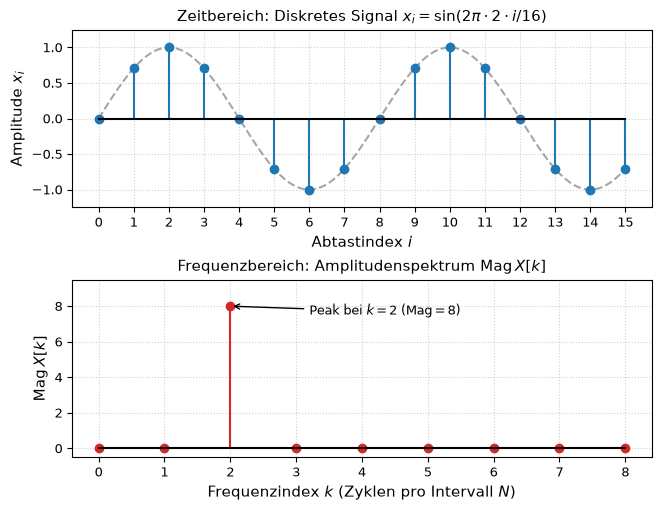

In [15]:
# === Plot erstellen ===
plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 12
})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6.5, 5.0), constrained_layout=True)

# Subplot 1: Zeitbereich
ax1.plot(t_continuous, x_continuous, color='gray', linestyle='--', alpha=0.7, label='Kontinuierlich')
markerline, stemlines, baseline = ax1.stem(i, x_discrete, basefmt='k-', linefmt='C0-', markerfmt='C0o')
stemlines.set_linewidth(1.5)
markerline.set_markersize(6)

ax1.set_title(r'Zeitbereich: Diskretes Signal $x_i = \sin(2\pi \cdot 2 \cdot i / 16)$')
ax1.set_xlabel('Abtastindex $i$')
ax1.set_ylabel(r'Amplitude $x_i$')
ax1.set_xticks(i)
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.set_ylim(-1.25, 1.25)

# Subplot 2: Frequenzbereich
markerline2, stemlines2, baseline2 = ax2.stem(k_values, Mag_X, basefmt='k-', linefmt='C3-', markerfmt='C3o')
stemlines2.set_linewidth(1.5)
markerline2.set_markersize(6)

ax2.set_title(r'Frequenzbereich: Amplitudenspektrum $\text{Mag}\,X[k]$')
ax2.set_xlabel('Frequenzindex $k$ (Zyklen pro Intervall $N$)')
ax2.set_ylabel(r'$\text{Mag}\,X[k]$')
ax2.set_xticks(k_values)
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.set_ylim(-0.5, 9.5)

ax2.annotate(r'Peak bei $k=2$ ($\text{Mag}=8$)', xy=(2, 8), xytext=(3.2, 7.5),
             arrowprops=dict(facecolor='black', arrowstyle='->', lw=1),
             fontsize=9)

plt.savefig('./abbildungen/dft_beispiel_sinus.pdf')
plt.show()